# SPC outlook verification on 80-km equal-area cells (CSV output)

For each hazard (tornado, wind, hail), each convective day, and each Day-1 1630 outlook, the notebook does four things:

1. Divides the US into forecast categories: every combination of probability level and CIG level the outlook drew.
2. Cuts each category along the edges of a fixed 80-km cell lattice (EPSG:5070, equal-area).
3. For every resulting piece, measures its area and how much of it lies within 40 km of a report at or above each intensity threshold.
4. Writes four CSV files per hazard (section 6). All scores are computed later in pandas from sums of these areas.

**Intensity thresholds** (SPC outlook page): tornado EF0, EF1, EF2, EF3, EF4 (EFU counted as EF0); wind 50, 56, 65, 74, 83 kt; hail 1.0, 1.5, 2.0, 3.5 in. The lowest threshold defines "any report". Footprints are cumulative: `obs_ef2` is the area within 40 km of a tornado rated EF2 **or higher**.

**Changes from `do_verf_outlooks.ipynb`** are listed in the last cell. In short:
- every Storm Events time zone is converted (MST was dropped);
- reports are matched to the exact valid period;
- CIG and probability polygons are separated using `LABEL`;
- every polygon at a level is used;
- empty outlook files count as 0% everywhere;
- areas are computed in an equal-area projection;
- polygons are no longer smoothed with a 10-km buffer.

In [1]:
import os, re, time
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import requests
import matplotlib.pyplot as plt

## Settings

In [2]:
DATES    = pd.date_range('2026-03-03', '2026-06-30', freq='D')    # convective days
HHMM     = '1630'                                                  # Day-1 issuance to verify

CRS_EQ   = 'EPSG:5070'        # NAD83 / CONUS Albers: equal-area, meters
CELL_M   = 80_000.0           # cell size (m)
BUFFER_M = 40_000.0           # report footprint radius (m), same as the outlook definition
GRID     = 1.0                # snap overlay results to a 1-m grid (section 3)

# hazard tag in SPC file names -> Storm Events type, thresholds (lowest = "any report"), column labels
HAZARDS = {
    'torn': dict(event_type='Tornado',           thresholds=[0, 1, 2, 3, 4],
                 labels=['ef0', 'ef1', 'ef2', 'ef3', 'ef4']),
    'wind': dict(event_type='Thunderstorm Wind', thresholds=[50, 56, 65, 74, 83],
                 labels=['50kt', '56kt', '65kt', '74kt', '83kt']),
    'hail': dict(event_type='Hail',              thresholds=[1.0, 1.5, 2.0, 3.5],
                 labels=['1p0in', '1p5in', '2p0in', '3p5in']),
}

DATA     = os.path.expanduser('~/Downloads/PPH_geojsons')
USA_FILE = f'{DATA}/usa_outline.geojson'
REG_FILE = f'{DATA}/bukovsky_regions_groups.geojson'
OTLK_DIR = os.path.expanduser('~/datasets/spc_outlooks_geojson/2026')
OUT_DIR  = os.path.expanduser('~/datasets/outlook_tiles_2026')
STORM_EVENTS = ('https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/'
                'StormEvents_details-ftp_v1.0_d2026_c20261026.csv.gz')   # check NCEI for the latest c-date
os.makedirs(OUT_DIR, exist_ok=True)

def outlook_path(day, haz):
    return os.path.join(OTLK_DIR, f'day1otlk_{day:%Y%m%d}_{HHMM}_{haz}.nolyr.geojson')

## 1. Download the outlooks
Skips files already on disk. The table shows the result for every day and hazard, so gaps are visible.

In [3]:
SPC_ARCHIVE = ('https://www.spc.noaa.gov/products/outlook/archive/{yyyy}/'
               'day1otlk_{ymd}_{hhmm}_{haz}.nolyr.geojson')

def fetch_spc_outlooks(dates, hazards, pause=0.5):
    os.makedirs(OTLK_DIR, exist_ok=True)
    log = []
    for d in dates:
        for haz in hazards:
            path = outlook_path(d, haz)
            if os.path.exists(path):
                log.append((d, haz, 'cached')); continue
            url = SPC_ARCHIVE.format(yyyy=d.year, ymd=f'{d:%Y%m%d}', hhmm=HHMM, haz=haz)
            try:
                r = requests.get(url, timeout=30)
            except requests.RequestException as e:
                log.append((d, haz, f'error: {e}')); continue
            if r.status_code == 200:
                with open(path, 'wb') as fh:
                    fh.write(r.content)
                log.append((d, haz, 'downloaded'))
            else:
                log.append((d, haz, f'HTTP {r.status_code}'))
            time.sleep(pause)
    return pd.DataFrame(log, columns=['date', 'hazard', 'status'])

dl = fetch_spc_outlooks(DATES, HAZARDS)
print(dl.groupby(['hazard', 'status']).size())
dl[~dl.status.isin(['cached', 'downloaded'])]

hazard  status    
hail    downloaded    120
torn    downloaded    120
wind    downloaded    120
dtype: int64


,date,hazard,status


## 2. Storm Events reports

Storm Events times are local standard time, and `CZ_TIMEZONE` gives the offset: `CST-6` means UTC = local + 6 h. The offset is read from the string itself, so every zone is handled; your original cells dropped MST-7. Anything that can't be parsed is counted and reported.

The magnitude `mag` is the EF rating for tornadoes (EFU = 0), knots for wind, and inches for hail. Events below the lowest threshold, or with no magnitude, are left out and counted.

In [4]:
def tz_offset_hours(tz):
    # Hours to ADD to Storm Events local time to get UTC: 'CST-6' -> 6, 'AKST-9' -> 9, 'GST10' -> -10
    m = re.fullmatch(r'([A-Za-z]+)(-?)(\d+)', str(tz).strip())
    if m is None:
        return np.nan
    n = float(m.group(3))
    return n if m.group(2) == '-' else -n

EF = {'EFU': 0, 'EF0': 0, 'EF1': 1, 'EF2': 2, 'EF3': 3, 'EF4': 4, 'EF5': 5}

def storm_events_table(storm, haz):
    spec = HAZARDS[haz]
    d = storm[storm.EVENT_TYPE == spec['event_type']].copy()
    off_h = d.CZ_TIMEZONE.map(tz_offset_hours)
    off = pd.to_timedelta(off_h, unit='h')
    d['t0'] = pd.to_datetime(d.BEGIN_DATE_TIME, format='%d-%b-%y %H:%M:%S') + off
    d['t1'] = pd.to_datetime(d.END_DATE_TIME,   format='%d-%b-%y %H:%M:%S') + off
    d['lon0'], d['lat0'] = d.BEGIN_LON, d.BEGIN_LAT
    d['lon1'], d['lat1'] = d.END_LON.fillna(d.BEGIN_LON), d.END_LAT.fillna(d.BEGIN_LAT)
    d['mag'] = d.TOR_F_SCALE.map(EF) if haz == 'torn' else pd.to_numeric(d.MAGNITUDE, errors='coerce')
    bad_t = d.t1 < d.t0
    d.loc[bad_t, 't1'] = d.loc[bad_t, 't0']
    no_tz, no_loc = off_h.isna(), d.lat0.isna() | d.lon0.isna()
    below = ~(d.mag >= spec['thresholds'][0])            # also True when mag is missing
    print(f"{haz}: {len(d)} events | time zones {d.CZ_TIMEZONE.value_counts().to_dict()}")
    print(f"   dropped: {no_tz.sum()} unparseable time zone, {no_loc.sum()} no location, "
          f"{below.sum()} below {spec['thresholds'][0]} or no magnitude; {bad_t.sum()} had end before begin")
    keep = ~no_tz & ~no_loc & ~below
    return d.loc[keep, ['EVENT_ID', 'mag', 'MAGNITUDE_TYPE', 'TOR_F_SCALE',
                        't0', 't1', 'lon0', 'lat0', 'lon1', 'lat1']].reset_index(drop=True)

storm = pd.read_csv(STORM_EVENTS, low_memory=False)
REPORTS = {haz: storm_events_table(storm, haz) for haz in HAZARDS}
for haz, r in REPORTS.items():
    print(haz, 'magnitudes:', r.mag.value_counts().sort_index().to_dict() if haz == 'torn'
          else r.mag.describe()[['min', '50%', 'max']].to_dict())

torn: 1133 events | time zones {'CST-6': 821, 'EST-5': 273, 'MST-7': 38, 'PST-8': 1}
   dropped: 0 unparseable time zone, 0 no location, 0 below 0 or no magnitude; 0 had end before begin
wind: 16857 events | time zones {'EST-5': 8122, 'CST-6': 7170, 'MST-7': 1482, 'PST-8': 77, 'AST-4': 5, 'SST-11': 1}
   dropped: 0 unparseable time zone, 0 no location, 491 below 50 or no magnitude; 0 had end before begin
hail: 6151 events | time zones {'CST-6': 4650, 'EST-5': 816, 'MST-7': 673, 'PST-8': 11, 'AST-4': 1}
   dropped: 0 unparseable time zone, 0 no location, 680 below 1.0 or no magnitude; 0 had end before begin
torn magnitudes: {0: 576, 1: 480, 2: 56, 3: 20, 4: 1}
wind magnitudes: {'min': 50.0, '50%': 52.0, 'max': 114.0}
hail magnitudes: {'min': 1.0, '50%': 1.25, 'max': 6.6}


## 3. Domain, cells, and the geometry helpers

**Cells:** squares on a fixed 80-km lattice. A cell's id is `i_j`, where i = floor(x / 80 km) and j = floor(y / 80 km) in EPSG:5070, so an id always means the same square. Edge cells are clipped to the US outline. Each cell is assigned to the Bukovsky regions (and region groups) that contain a point inside it.

**Precision:** every intersection, union and difference is snapped to a 1-m grid (`grid_size=GRID`), as `set_precision(1.)` did in your original code. Without it, floating-point overlay occasionally counted a band twice inside a cell; that happened in 3 of about 178,000 cases in testing.

In [5]:
def to_eq(g):
    return (g if g.crs else g.set_crs(4326)).to_crs(CRS_EQ)

usa = to_eq(gpd.read_file(USA_FILE))
domain = shapely.set_precision(shapely.make_valid(usa.union_all()), GRID)

def make_cells(domain, cell_m):
    minx, miny, maxx, maxy = domain.bounds
    i_rng = np.arange(np.floor(minx / cell_m), np.ceil(maxx / cell_m)).astype(int)
    j_rng = np.arange(np.floor(miny / cell_m), np.ceil(maxy / cell_m)).astype(int)
    ii, jj = [a.ravel() for a in np.meshgrid(i_rng, j_rng)]
    boxes = shapely.box(ii * cell_m, jj * cell_m, (ii + 1) * cell_m, (jj + 1) * cell_m)
    g = gpd.GeoDataFrame({'cell_id': [f'{i}_{j}' for i, j in zip(ii, jj)], 'i': ii, 'j': jj,
                          'x_center': (ii + 0.5) * cell_m, 'y_center': (jj + 0.5) * cell_m},
                         geometry=shapely.intersection(boxes, domain, grid_size=GRID), crs=CRS_EQ)
    g = g[~g.is_empty & (g.area > 0)].reset_index(drop=True)
    g['area_km2'] = g.area / 1e6
    ll = gpd.GeoSeries(gpd.points_from_xy(g.x_center, g.y_center), crs=CRS_EQ).to_crs(4326)
    g['lon'], g['lat'] = ll.x.values, ll.y.values
    return g

cells = make_cells(domain, CELL_M)
regions = to_eq(gpd.read_file(REG_FILE))
pts = cells[['cell_id']].set_geometry(cells.representative_point())
cell_regions = (gpd.sjoin(pts, regions[['names', 'group', 'geometry']], predicate='within')
                [['cell_id', 'names', 'group']].rename(columns={'names': 'region'}))
print(f'{len(cells)} cells covering {cells.area_km2.sum():,.0f} km2 (domain {domain.area/1e6:,.0f} km2)')

def polygonal(g):
    # Keep only the area parts of a geometry. Two polygons that touch along an edge can intersect
    # in a line; shapely refuses to mix lines and polygons in later steps.
    if g.is_empty or g.geom_type in ('Polygon', 'MultiPolygon'):
        return g
    parts = [p for p in shapely.get_parts(g) if p.geom_type in ('Polygon', 'MultiPolygon')]
    return shapely.union_all(parts, grid_size=GRID) if parts else shapely.Polygon()

def union(geoms):
    return polygonal(shapely.union_all(geoms, grid_size=GRID)) if geoms else shapely.Polygon()

def clean(geom):
    return polygonal(shapely.set_precision(shapely.make_valid(geom), GRID))

def overlay(fn, a, b):
    # intersection or difference on a 1-m grid, keeping only polygon parts
    return polygonal(fn(a, b, grid_size=GRID))

1456 cells covering 8,499,418 km2 (domain 8,499,418 km2)


## 4. Outlook file to forecast categories

`read_outlook` sorts the features using `LABEL`. A label like `0.05` is a probability (5%) and `CIG1` is an intensity group. `DN` can't be used because CIG polygons reuse it (on 28 Apr the CIG1 feature had `DN = 2`, the same as the 2% band).

`categories` turns the polygons into non-overlapping pieces of the domain:
- **Probability band:** "at or above L" is the union of every probability polygon labeled ≥ L, and the band for L is that area minus the area for the next level up. This works whether a file stores each level as a full area or as a ring, and it uses every polygon at a level.
- **CIG band:** built the same way from the CIG polygons, so a point's CIG is the highest CIG drawn over it. CIG 0 means no CIG.
- **Category:** the overlap of one probability band with one CIG band. Every point in the domain falls in exactly one category; the rest of the domain is (0%, CIG 0).

An empty file (no features) has no attributes. Its valid period comes from the file name, and the whole domain is (0%, CIG 0).

In [6]:
def read_outlook(path, day):
    g = to_eq(gpd.read_file(path))
    prob, cig, unknown = {}, {}, []
    for _, r in g.iterrows():
        if r.geometry is None or r.geometry.is_empty:
            continue
        lab = str(r.get('LABEL', '')).strip().upper()
        if lab.startswith('CIG'):
            cig.setdefault(int(lab[3:]), []).append(clean(r.geometry))
            continue
        try:
            prob.setdefault(int(round(float(lab) * 100)), []).append(clean(r.geometry))
        except ValueError:
            unknown.append(lab)
    if unknown:
        print(f'   WARNING {os.path.basename(path)}: unrecognized LABELs {unknown}')
    if len(g) and 'VALID' in g:
        meta = dict(valid=pd.to_datetime(g.VALID.iloc[0], format='%Y%m%d%H%M'),
                    expire=pd.to_datetime(g.EXPIRE.iloc[0], format='%Y%m%d%H%M'),
                    issued=pd.to_datetime(g.ISSUE.iloc[0], format='%Y%m%d%H%M'),
                    forecaster=g.FORECASTER.iloc[0] if 'FORECASTER' in g else None)
    else:
        meta = dict(valid=day + pd.Timedelta(hours=int(HHMM[:2]), minutes=int(HHMM[2:])),
                    expire=day + pd.Timedelta(days=1, hours=12), issued=pd.NaT, forecaster=None)
    meta.update(n_features=len(g), prob_polys=prob, cig_polys=cig)
    return meta

def bands(polys, domain):
    # {level: [polygons]} -> {level: exclusive band}, including level 0 = rest of the domain
    levels = sorted(set(polys) | {0})
    ge = {L: overlay(shapely.intersection, union([p for k, ps in polys.items() if k >= L for p in ps]), domain)
          for L in levels[1:]}
    ge[0] = domain
    out = {}
    for k, L in enumerate(levels):
        above = ge[levels[k + 1]] if k + 1 < len(levels) else shapely.Polygon()
        b = overlay(shapely.difference, ge[L], above)
        if not b.is_empty:
            out[L] = b
    return out

def categories(fc, domain):
    # GeoDataFrame with one row per (prob, cig) combination present in the outlook
    pb, cb = bands(fc['prob_polys'], domain), bands(fc['cig_polys'], domain)
    rows = []
    for p, pg in pb.items():
        for c, cg in cb.items():
            g = overlay(shapely.intersection, pg, cg)
            if not g.is_empty and g.area > 0:
                rows.append((p, c, g))
    return gpd.GeoDataFrame(rows, columns=['prob', 'cig', 'geometry'], crs=CRS_EQ)

## 5. Reports to footprints, and categories to cell pieces

`reports_in_window` keeps the part of each report inside the outlook's valid period. A track that starts at 16:10Z is cut at its 16:30Z position, by linear interpolation along the track (the same assumption as the hourly splitting in your notebook). Points are kept if they fall in the window.

`footprints` buffers those pieces by 40 km and unions them **once per threshold**, using every report at or above that threshold. The footprints are nested: the EF2+ footprint lies inside the EF1+ footprint.

`tile_rows` cuts each category along the cell edges. `cells.sindex.query` finds the cells a category touches, so only those are intersected. Each piece becomes one row with its area and the area of each footprint inside it.

`report_categories` records, for each report piece, the highest probability and the highest CIG it touches. For a track, these are taken separately along its length, so the two can come from different spots on the track.

In [7]:
def reports_in_window(ev, t_start, t_end):
    is_point = (ev.t1 <= ev.t0).to_numpy()
    keep = np.where(is_point, (ev.t0 >= t_start) & (ev.t0 < t_end), (ev.t0 < t_end) & (ev.t1 > t_start))
    e = ev[keep].copy()
    if e.empty:
        return gpd.GeoDataFrame(e, geometry=[], crs=4326)
    dur = (e.t1 - e.t0).dt.total_seconds().to_numpy()
    ta = e.t0.where(e.t0 > t_start, t_start)             # clip the start of the track to the window
    tb = e.t1.where(e.t1 < t_end, t_end)                 # clip the end
    safe = np.where(dur > 0, dur, 1.0)
    wa = np.where(dur > 0, (ta - e.t0).dt.total_seconds().to_numpy() / safe, 0.0)
    wb = np.where(dur > 0, (tb - e.t0).dt.total_seconds().to_numpy() / safe, 0.0)
    e['lon_a'], e['lat_a'] = e.lon0 + wa * (e.lon1 - e.lon0), e.lat0 + wa * (e.lat1 - e.lat0)
    e['lon_b'], e['lat_b'] = e.lon0 + wb * (e.lon1 - e.lon0), e.lat0 + wb * (e.lat1 - e.lat0)
    geoms = [shapely.Point(a, b) if (a == c and b == d) else shapely.LineString([(a, b), (c, d)])
             for a, b, c, d in zip(e.lon_a, e.lat_a, e.lon_b, e.lat_b)]
    return gpd.GeoDataFrame(e, geometry=geoms, crs=4326)

def footprints(rep, haz, domain):
    # {label: area within BUFFER_M of any report with mag >= threshold}
    spec = HAZARDS[haz]
    disks = rep.to_crs(CRS_EQ).buffer(BUFFER_M) if len(rep) else gpd.GeoSeries([], crs=CRS_EQ)
    out = {}
    for thr, lab in zip(spec['thresholds'], spec['labels']):
        sel = disks[(rep.mag >= thr).to_numpy()].values if len(rep) else []
        out[lab] = overlay(shapely.intersection, union(list(sel)), domain)
    return out

def tile_rows(cats, fps, cells):
    cell_geom, cell_ids = cells.geometry.values, cells.cell_id.values
    parts = []
    for p, c, cat in cats[['prob', 'cig', 'geometry']].itertuples(index=False):
        idx = cells.sindex.query(cat, predicate='intersects')            # cells this category touches
        pieces = np.array([polygonal(p) for p in shapely.intersection(cell_geom[idx], cat, grid_size=GRID)])
        df = pd.DataFrame({'cell_id': cell_ids[idx], 'prob': p, 'cig': c,
                           'area_km2': shapely.area(pieces) / 1e6})
        for lab, fp in fps.items():
            df[f'obs_{lab}'] = (0.0 if fp.is_empty else
                                shapely.area(shapely.intersection(pieces, fp, grid_size=GRID)) / 1e6)
        parts.append(df)
    out = pd.concat(parts, ignore_index=True)
    return out[out.area_km2 > 1e-6]

def report_categories(rep, cats):
    r = rep.to_crs(CRS_EQ)[['EVENT_ID', 'mag', 't0', 't1', 'lon_a', 'lat_a', 'lon_b', 'lat_b', 'geometry']]
    j = gpd.sjoin(r, cats[['prob', 'cig', 'geometry']], how='left', predicate='intersects')
    best = j.groupby(level=0)[['prob', 'cig']].max()                  # NaN = outside the domain
    return r.drop(columns='geometry').join(best)

## 6. Run, and write the CSV files

For each hazard, four files go to `OUT_DIR`:

| File | One row per | Main columns |
| --- | --- | --- |
| `cells.csv`, `cell_regions.csv` | cell (and cell–region pair) | cell_id, lon, lat, area_km2; region, group |
| `outlooks_{haz}.csv` | outlook file (day) | status, valid/expire/issued, forecaster, max_prob, max_cig, area at or above each probability level, area of each CIG level, report counts |
| `tiles_{haz}.csv` | day × cell × probability × CIG piece | area_km2, obs_* (footprint area at or above each threshold) |
| `reports_{haz}.csv` | report piece inside the valid period | EVENT_ID, mag, times, clipped positions, prob and cig at the report |

A missing file gives a `missing` row in `outlooks_{haz}.csv` and no tile rows. An empty file gives a single (0%, CIG 0) category covering the domain.

In [8]:
cells.drop(columns='geometry').to_csv(f'{OUT_DIR}/cells.csv', index=False)
cell_regions.to_csv(f'{OUT_DIR}/cell_regions.csv', index=False)

def outlook_summary(fc, cats, rep, haz):
    s = dict(valid=fc['valid'], expire=fc['expire'], issued=fc['issued'], forecaster=fc['forecaster'],
             n_features=fc['n_features'],
             max_prob=max(fc['prob_polys'], default=0), max_cig=max(fc['cig_polys'], default=0))
    for L in sorted(cats.prob.unique()):
        if L > 0:
            s[f'area_ge{L}_km2'] = cats.loc[cats.prob >= L].area.sum() / 1e6
    for k in sorted(cats.cig.unique()):
        if k > 0:
            s[f'area_cig{k}_km2'] = cats.loc[cats.cig == k].area.sum() / 1e6
    for thr, lab in zip(HAZARDS[haz]['thresholds'], HAZARDS[haz]['labels']):
        s[f'n_rep_{lab}'] = int((rep.mag >= thr).sum())
    return s

t_begin = time.time()
for haz in HAZARDS:
    summ, tiles, reps = [], [], []
    for day in DATES:
        path = outlook_path(day, haz)
        row = dict(date=day.date(), hazard=haz, file=os.path.basename(path))
        if not os.path.exists(path):
            summ.append({**row, 'status': 'missing'}); continue
        fc = read_outlook(path, day)
        cats = categories(fc, domain)
        rep = reports_in_window(REPORTS[haz], fc['valid'], fc['expire'])
        tr = tile_rows(cats, footprints(rep, haz, domain), cells)
        tr.insert(0, 'date', day.date())
        tiles.append(tr)
        if len(rep):
            rc = report_categories(rep, cats)
            rc.insert(0, 'date', day.date())
            reps.append(rc)
        summ.append({**row, 'status': 'ok' if fc['n_features'] else 'empty', **outlook_summary(fc, cats, rep, haz)})
    pd.DataFrame(summ).to_csv(f'{OUT_DIR}/outlooks_{haz}.csv', index=False)
    if tiles:
        pd.concat(tiles, ignore_index=True).to_csv(f'{OUT_DIR}/tiles_{haz}.csv', index=False)
    if reps:
        pd.concat(reps, ignore_index=True).to_csv(f'{OUT_DIR}/reports_{haz}.csv', index=False)
    print(f'{haz}: {len(tiles)} outlooks scored, {sum(len(t) for t in tiles):,} tile rows, '
          f'{sum(len(r) for r in reps):,} report pieces ({time.time() - t_begin:.0f} s)')

torn: 120 outlooks scored, 183,117 tile rows, 871 report pieces (5 s)
wind: 120 outlooks scored, 191,042 tile rows, 10,188 report pieces (12 s)
hail: 120 outlooks scored, 188,602 tile rows, 4,525 report pieces (18 s)


## 7. Reading the output

Everything below uses only the CSV files, so it can run in a fresh session.

First, a check: on each day, the pieces of a cell must add up to the cell's area, and the footprints must be nested (an EF2+ area can't be bigger than the EF1+ area).

In [9]:
haz = 'torn'
labs = HAZARDS[haz]['labels']
obs = [f'obs_{l}' for l in labs]
cells_df = pd.read_csv(f'{OUT_DIR}/cells.csv')
ol = pd.read_csv(f'{OUT_DIR}/outlooks_{haz}.csv', parse_dates=['date'])
t  = pd.read_csv(f'{OUT_DIR}/tiles_{haz}.csv', parse_dates=['date'])
rp = pd.read_csv(f'{OUT_DIR}/reports_{haz}.csv', parse_dates=['date'])

chk = t.groupby(['date', 'cell_id']).area_km2.sum().reset_index().merge(cells_df[['cell_id', 'area_km2']],
                                                                        on='cell_id', suffixes=('', '_cell'))
err = (chk.area_km2 - chk.area_km2_cell).abs() / chk.area_km2_cell
print(f'piece areas vs cell area: max relative error {err.max():.1e}, cells off by >0.1%: {(err > 1e-3).sum()}')
excess = max((t[b] - t[a]).max() for a, b in zip(obs[:-1], obs[1:]))
print(f'footprints nested (higher threshold never larger): largest excess {excess:.4f} km2 '
      f'(anything under ~0.01 km2 is 1-m grid rounding)')
print(ol.status.value_counts().to_dict())

piece areas vs cell area: max relative error 2.6e-03, cells off by >0.1%: 1
footprints nested (higher threshold never larger): largest excess 0.0052 km2 (anything under ~0.01 km2 is 1-m grid rounding)
{'ok': 120}


### General characteristics of the outlooks

max_cig,0,1,2,All
max_prob,,,,
0,28,0,0,28
2,33,4,0,37
5,14,20,0,34
10,1,11,3,15
15,0,1,5,6
All,76,36,8,120


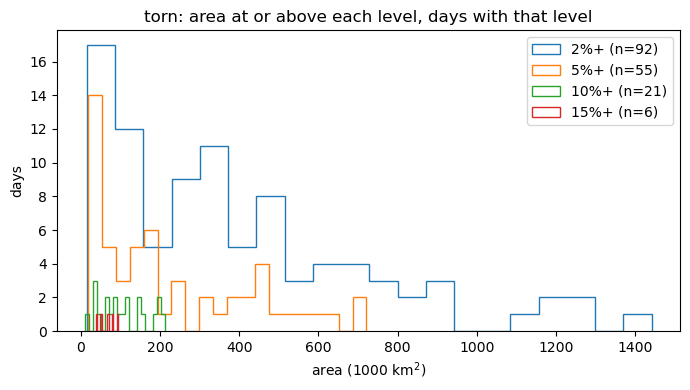

In [10]:
ok = ol[ol.status != 'missing']
display(pd.crosstab(ok.max_prob, ok.max_cig, margins=True))          # highest level drawn, per day

area_cols = [c for c in ok.columns if c.startswith('area_ge')]
fig, ax = plt.subplots(figsize=(7, 4))
for c in area_cols:
    v = ok[c].dropna()
    if len(v):
        ax.hist(v / 1e3, bins=20, histtype='step', label=f"{c[7:-4]}%+ (n={len(v)})")
ax.set(xlabel='area (1000 km$^2$)', ylabel='days', title=f'{haz}: area at or above each level, days with that level')
ax.legend(); plt.tight_layout(); plt.show()

### Conditional and unconditional intensity by forecast category

Within a category:
- **Unconditional:** P(report ≥ threshold within 40 km) = obs / area.
- **Conditional on a report occurring:** P(≥ threshold | any report within 40 km) = obs / obs at the lowest threshold.

Both are pooled over all days, so they are area-weighted. The last line puts confidence intervals on the conditional fractions by resampling whole days.

In [11]:
g = t.groupby(['prob', 'cig'])[['area_km2'] + obs].sum()
g['n_days'] = t.groupby(['prob', 'cig']).date.nunique()
uncond = g[obs].div(g.area_km2, axis=0)
cond   = g[obs].div(g[obs[0]], axis=0)
display(g[['n_days', 'area_km2']].round(0))
display(uncond.round(4))
display(cond.round(3))

def boot_cond(t, num, den, n_boot=1000, seed=0):
    # 90% interval for sum(num)/sum(den) per category, resampling whole days
    rng = np.random.default_rng(seed)
    daily = t.groupby(['prob', 'cig', 'date'])[[num, den]].sum()
    out = {}
    for key, d in daily.groupby(level=[0, 1]):
        x, y = d[num].to_numpy(), d[den].to_numpy()
        idx = rng.integers(0, len(x), (n_boot, len(x)))
        with np.errstate(invalid='ignore', divide='ignore'):
            r = x[idx].sum(1) / y[idx].sum(1)
        out[key] = np.nanpercentile(r, [5, 95]) if np.isfinite(r).any() else [np.nan, np.nan]
    return pd.DataFrame(out, index=['p05', 'p95']).T

display(boot_cond(t, 'obs_ef2', 'obs_ef0').round(3))   # e.g. P(EF2+ | tornado) with 90% intervals

n_days     area_km2
prob cig                     
0    0       120  983587199.0
     1        17      12257.0
2    0        92   20079311.0
     1        42    3768916.0
5    0        44    1983016.0
     1        40    8240560.0
     2         3      14481.0
10   0         4      57494.0
     1        20    1511742.0
     2         7     273383.0
15   1         4      77119.0
     2         5     324744.0

obs_ef0  obs_ef1  obs_ef2  obs_ef3  obs_ef4
prob cig                                             
0    0     0.0004   0.0001   0.0000   0.0000   0.0000
     1     0.0061   0.0061   0.0000   0.0000   0.0000
2    0     0.0259   0.0154   0.0033   0.0003   0.0000
     1     0.0320   0.0202   0.0038   0.0010   0.0003
5    0     0.0666   0.0423   0.0000   0.0000   0.0000
     1     0.0855   0.0520   0.0129   0.0032   0.0005
     2     0.3720   0.0676   0.0013   0.0000   0.0000
10   0     0.0627   0.0627   0.0000   0.0000   0.0000
     1     0.1227   0.0783   0.0166   0.0106   0.0004
     2     0.3500   0.2204   0.0609   0.0126   0.0000
15   1     0.4093   0.2826   0.0263   0.0001   0.0000
     2     0.4521   0.3052   0.1146   0.0890   0.0000

obs_ef0  obs_ef1  obs_ef2  obs_ef3  obs_ef4
prob cig                                             
0    0        1.0    0.355    0.032    0.000    0.000
     1        1.0    1.000    0.000    0.000    0.000
2    0        1.0    0.595    0.126    0.011    0.000
     1        1.0    0.631    0.119    0.030    0.009
5    0        1.0    0.635    0.000    0.000    0.000
     1        1.0    0.608    0.151    0.038    0.006
     2        1.0    0.182    0.003    0.000    0.000
10   0        1.0    1.000    0.000    0.000    0.000
     1        1.0    0.638    0.135    0.086    0.003
     2        1.0    0.630    0.174    0.036    0.000
15   1        1.0    0.690    0.064    0.000    0.000
     2        1.0    0.675    0.253    0.197    0.000

p05    p95
0  0  0.001  0.072
   1  0.000  0.000
2  0  0.059  0.199
   1  0.023  0.306
5  0  0.000  0.001
   1  0.092  0.211
   2  0.000  0.271
10 0  0.000  0.000
   1  0.049  0.248
   2  0.107  0.225
15 1  0.000  0.255
   2  0.089  0.393

In [12]:
# Report-count version: ratings of the reports, by the highest category each report touched
display(pd.crosstab([rp.prob, rp.cig], rp.mag, margins=True))

mag         0    1   2   3  4  All
prob cig                          
0    0     61   28   3   0  0   92
2    0     76   70  11   1  0  158
     1     21   23   2   0  0   46
5    0     29   35   0   0  0   64
     1    139  141  19   6  1  306
     2      1    0   0   0  0    1
10   0      0    1   0   0  0    1
     1     42   32   2   4  0   80
     2     15   13   2   0  0   30
15   1      8    4   1   0  0   13
     2     33   36   3   8  0   80
All       425  383  43  19  1  871

In [13]:
# Calibration of the coverage probabilities (any report), from the same columns
cov = t.groupby('prob')[['area_km2', obs[0]]].sum()
cov['obs_freq'] = cov[obs[0]] / cov.area_km2
display(cov)
f, A, O = cov.index / 100, cov.area_km2, cov[obs[0]]
obar = O.sum() / A.sum()
bs = ((f**2) * A - 2 * f * O + O).sum() / A.sum()
print(f'BS = {bs:.5f}, BSS vs sample climatology = {1 - bs / (obar * (1 - obar)):.4f}')

,area_km2,obs_ef0,obs_freq
prob,,,
0,9.835995e+08,369738.669165,0.000376
2,2.384823e+07,640536.878414,0.026859
5,1.023806e+07,842257.166045,0.082267
10,1.842620e+06,284820.039045,0.154573
15,4.018630e+05,178368.438633,0.443854


BS = 0.00212, BSS vs sample climatology = 0.0660


## 8. Verification scores from the tile output

Every common score can be built from sums of `area_km2` and the `obs_*` columns, for any subset of rows (a day, a month, a region, a forecast category). For a piece with forecast probability f, area A, and observed area O (the part within 40 km of a report):

- **Squared error** over the piece: f²·A − 2·f·O + O. Summed and divided by the total area, this gives the Brier score.
- **Contingency table** at a threshold p (forecast "yes" where f ≥ p):
    - hits = O where f ≥ p
    - false alarms = A − O where f ≥ p
    - misses = O where f < p
    - correct nulls = A − O where f < p

    POD, FAR, SR, CSI, frequency bias, POFD and HSS follow from these four areas.
- **ROC curve:** POD against POFD as the threshold steps down through the probability levels. AUC is the area under it.

`level_table` sums the areas for each forecast value, optionally within groups. The score functions then work on that small table.

In [14]:
def level_table(t, obs_col, fcol='prob', area_col='area_km2', by=None):
    # Sum area and observed area for each forecast value (optionally within groups `by`)
    keys = (by or []) + [fcol]
    g = t.groupby(keys)[[area_col, obs_col]].sum().reset_index()
    return g.rename(columns={fcol: 'fcst', area_col: 'A', obs_col: 'O'})

def div(a, b):
    return a / b if b > 0 else np.nan

def prob_scores(lt):
    # Brier score and decomposition, BSS against the sample climatology, ROC area. fcst in percent.
    f, A, O = lt.fcst.to_numpy() / 100, lt.A.to_numpy(), lt.O.to_numpy()
    N, n_obs = A.sum(), O.sum()
    obar = n_obs / N
    bs = (f**2 * A - 2 * f * O + O).sum() / N
    oj = np.divide(O, A, out=np.full(len(O), np.nan), where=A > 0)
    rel = np.nansum(A * (f - oj)**2) / N
    res = np.nansum(A * (oj - obar)**2) / N
    unc = obar * (1 - obar)
    order = np.argsort(-f)                                   # highest probability first
    pod = np.r_[0, np.cumsum(O[order]) / n_obs] if n_obs > 0 else np.full(len(f) + 1, np.nan)
    pofd = np.r_[0, np.cumsum((A - O)[order]) / (N - n_obs)]
    auc = np.sum(np.diff(pofd) * (pod[1:] + pod[:-1]) / 2)
    return pd.Series(dict(BS=bs, BSS=div(unc - bs, unc), REL=rel, RES=res, UNC=unc,
                          obs_freq=obar, mean_fcst=(f * A).sum() / N, AUC=auc, area_km2=N))

def contingency(lt):
    # One row per threshold: forecast "yes" where fcst >= threshold
    A, O = lt.A.sum(), lt.O.sum()
    rows = []
    for p in sorted(lt.fcst.unique())[1:]:                   # the lowest value is never a "yes"
        yes = lt.fcst >= p
        a, b = lt.O[yes].sum(), (lt.A - lt.O)[yes].sum()     # hits, false alarms
        c, d = O - a, (A - O) - b                            # misses, correct nulls
        n = a + b + c + d
        expected = ((a + b) * (a + c) + (c + d) * (b + d)) / n
        rows.append(dict(threshold=p, hits=a, false_alarms=b, misses=c, correct_nulls=d,
                         POD=div(a, a + c), FAR=div(b, a + b), SR=div(a, a + b), CSI=div(a, a + b + c),
                         bias=div(a + b, a + c), POFD=div(b, b + d), HSS=div(a + d - expected, n - expected)))
    return pd.DataFrame(rows)

In [15]:
# Coverage probabilities verified against any report, for each hazard
for haz, spec in HAZARDS.items():
    th = pd.read_csv(f'{OUT_DIR}/tiles_{haz}.csv', parse_dates=['date'])
    lt = level_table(th, f"obs_{spec['labels'][0]}")
    print(f'\n=== {haz}: probabilities vs any report (>= {spec["thresholds"][0]}) ===')
    display(prob_scores(lt).round(5).to_frame().T)
    display(contingency(lt).round(4))


=== torn: probabilities vs any report (>= 0) ===


,BS,BSS,REL,RES,UNC,obs_freq,mean_fcst,AUC,area_km2
0,0.00212,0.06599,0.00005,0.0002,0.00227,0.00227,0.00121,0.90883,1.019930e+09


,threshold,hits,false_alarms,misses,correct_nulls,POD,FAR,SR,CSI,bias,POFD,HSS
0,2,1.945983e+06,3.438478e+07,3.697387e+05,9.832297e+08,0.8403,0.9464,0.0536,0.0530,15.6887,0.0338,0.0969
1,5,1.305446e+06,1.117709e+07,1.010276e+06,1.006437e+09,0.5637,0.8954,0.1046,0.0968,5.3903,0.0110,0.1733
2,10,4.631885e+05,1.781295e+06,1.852533e+06,1.015833e+09,0.2000,0.7936,0.2064,0.1131,0.9692,0.0018,0.2014
3,15,1.783684e+05,2.234946e+05,2.137353e+06,1.017391e+09,0.0770,0.5561,0.4439,0.0702,0.1735,0.0002,0.1307



=== wind: probabilities vs any report (>= 50) ===


,BS,BSS,REL,RES,UNC,obs_freq,mean_fcst,AUC,area_km2
0,0.01302,0.17725,0.00034,0.00314,0.01583,0.01608,0.00979,0.91449,1.019930e+09


,threshold,hits,false_alarms,misses,correct_nulls,POD,FAR,SR,CSI,bias,POFD,HSS
0,5,1.448177e+07,8.566975e+07,1.923054e+06,9.178556e+08,0.8828,0.8554,0.1446,0.1419,6.1050,0.0854,0.2271
1,15,9.912657e+06,2.678459e+07,6.492170e+06,9.767408e+08,0.6043,0.7299,0.2701,0.2295,2.2370,0.0267,0.3591
2,30,3.566625e+06,3.892529e+06,1.283820e+07,9.996329e+08,0.2174,0.5218,0.4782,0.1757,0.4547,0.0039,0.2918
3,45,7.470833e+05,3.634368e+05,1.565774e+07,1.003162e+09,0.0455,0.3273,0.6727,0.0446,0.0677,0.0004,0.0834
4,60,1.233039e+05,3.078988e+04,1.628152e+07,1.003495e+09,0.0075,0.1998,0.8002,0.0075,0.0094,0.0000,0.0146



=== hail: probabilities vs any report (>= 1.0) ===


,BS,BSS,REL,RES,UNC,obs_freq,mean_fcst,AUC,area_km2
0,0.00636,0.13424,0.00001,0.001,0.00735,0.0074,0.00645,0.92211,1.019930e+09


,threshold,hits,false_alarms,misses,correct_nulls,POD,FAR,SR,CSI,bias,POFD,HSS
0,5,6.689402e+06,6.675007e+07,8.599805e+05,9.456308e+08,0.8861,0.9089,0.0911,0.0900,9.7279,0.0659,0.1538
1,15,4.421304e+06,1.874052e+07,3.128078e+06,9.936403e+08,0.5857,0.8091,0.1909,0.1682,3.0680,0.0185,0.2799
2,30,1.320381e+06,2.442432e+06,6.229001e+06,1.009938e+09,0.1749,0.6491,0.3509,0.1321,0.4984,0.0024,0.2297
3,45,1.215123e+05,8.408684e+04,7.427870e+06,1.012297e+09,0.0161,0.4090,0.5910,0.0159,0.0272,0.0001,0.0310


In [ ]:
# The same functions on subsets: by month, by region, and day by day (tornado)
t['month'] = t.date.dt.to_period('M')
by_month = level_table(t, 'obs_ef0', by=['month']).groupby('month').apply(prob_scores, include_groups=False)
display(by_month[['BS', 'BSS', 'REL', 'RES', 'AUC', 'obs_freq']].round(4))

reg = pd.read_csv(f'{OUT_DIR}/cell_regions.csv')
tr = t.merge(reg[['cell_id', 'region']], on='cell_id')          # a cell can be in a region and its group
by_region = level_table(tr, 'obs_ef0', by=['region']).groupby('region').apply(prob_scores, include_groups=False)
display(by_region[['BS', 'BSS', 'AUC', 'obs_freq', 'area_km2']].round(4))

daily = level_table(t, 'obs_ef0', by=['date']).groupby('date').apply(prob_scores, include_groups=False)
daily_ct = (level_table(t, 'obs_ef0', by=['date']).groupby('date').apply(contingency, include_groups=False)
            .reset_index(level=0))
display(daily_ct[daily_ct.threshold == 5][['date', 'POD', 'SR', 'CSI', 'bias']].head())

### Scoring the CIG levels

A CIG level isn't a probability, so it doesn't get a Brier score, but the same tools apply **given that a report occurred**. Replace the area with the "any report" footprint and the observed area with the footprint at a higher threshold:

- forecast "yes" = CIG ≥ k;
- event = a report at or above the threshold (e.g. EF2+) within 40 km;
- the sample = the area within 40 km of any report.

A hit is then area near an EF2+ tornado inside CIG ≥ k. A false alarm is area near tornadoes, all weaker than EF2, inside CIG ≥ k. POD, SR and CSI measure whether the CIG areas pick out where the stronger tornadoes happened, among places that had tornadoes.

In [16]:
# Conditional contingency: did CIG >= k separate EF2+ (EF3+) tornado area from weaker tornado area?
for thr in ['obs_ef2', 'obs_ef3']:
    lt = level_table(t, thr, fcol='cig', area_col='obs_ef0')
    print(f'CIG vs {thr}, given any tornado within 40 km')
    display(contingency(lt).round(3))

CIG vs obs_ef2, given any tornado within 40 km


,threshold,hits,false_alarms,misses,correct_nulls,POD,FAR,SR,CSI,bias,POFD,HSS
0,1,201878.114,1088507.553,77451.255,947884.270,0.723,0.844,0.156,0.148,4.620,0.535,0.073
1,2,53877.024,193991.687,225452.345,1842400.136,0.193,0.783,0.217,0.114,0.887,0.095,0.103


CIG vs obs_ef3, given any tornado within 40 km


,threshold,hits,false_alarms,misses,correct_nulls,POD,FAR,SR,CSI,bias,POFD,HSS
0,1,78604.521,1211781.146,5680.795,1019654.729,0.933,0.939,0.061,0.061,15.310,0.543,0.049
1,2,32355.481,215513.229,51929.835,2015922.646,0.384,0.869,0.131,0.108,2.941,0.097,0.149


## Notes on `do_verf_outlooks.ipynb`

**Fixed here**
1. **MST-7 reports are dropped** (cells 5, 7, 8). `df_*_mst` is built but left out of `pd.concat`. Zones not on the hand-made list are also dropped silently.
2. **Reports land in the wrong window.**
    - Times are rounded up to the hour (`dt.ceil('h')`) and filtered with `>= VALID` and `<= EXPIRE`, so a report at 11:30Z on day D counts in both day D−1 and day D.
    - For the 1630 outlook, a report at 16:05Z becomes 17:00 and is counted although it came before the valid time.
3. **CIG polygons can be counted as probability.** CIG1 has `DN = 2`, the same as the 2% band. Cell 9 (`DN == lvl ... .iloc[0]`) depends on the order of features in the file. Cell 12 (`DN >= level`) adds the CIG1 area to the 2% area.
4. **Only the first polygon at a level is used** (`.iloc[0]` in cell 9).
5. **Empty outlook files are skipped.** Reading `VALID` fails and the bare `except: continue` skips the day, which drops misses on no-risk days. I'm inferring that no-risk files are empty; please confirm with one day.
6. **Areas are not equal-area.** `+proj=lcc +lat_1=25 +lat_2=25` inflates areas by 7.5% at 40°N and 21% at 49°N.
7. **The 10-km buffer (`.buffer(10000).buffer(-10000)`) changes the forecast polygons.** It fills gaps narrower than about 20 km, and because it is applied to each level separately, neighboring bands can overlap.

**Other issues**
- Cell 9: `sys` is not imported, and the loop variable `range` shadows the built-in.
- Cells 5, 7, 8: values are written by column position (`iloc[row, 44]`). Use column names.
- Cell 7: `'all'` and `'svr'` wind are the same set (both ≥ 50 kt).
- Cell 10: `.mean()` over rows averages across the 8 probability levels as well as the days, dividing the MSE by 8. The index is also not a datetime unless the commented-out `set_index` is run.
- Cell 12: `PROB_COLORS` has no 10% entry. POD and SR return 0 instead of NaN when there are no reports. The window has the same rounding issue as item 2.